# Yosemite temperatures: from a straight line to an RBF model

Pre-class work: model 5-minute air temperature from **Yosemite Village 12 W** (NOAA U.S. Climate Reference
Network station 53150), 2011–2016. The booklet's four code cells are labelled `CODE CELL 1`–`4` in banner
comments. Cell 1 is the booklet's code unchanged apart from a download step; Cells 2–4 are written here.

| Model | R² | RMSE |
|---|---|---|
| Cell 1 straight line (time of day only) | 0.017 | 7.75 °C |
| RBF model, all readings it was fitted on | **0.933** | 2.03 °C |
| RBF model, whole days it never saw | **0.884** | 2.62 °C |
| Best setting from the Cell 4 search (RBF every 2 days), days it never saw | **0.931** | |
| Same setting refitted, all readings | **0.961** | 1.55 °C |

The extension benchmark is R² ≈ 0.82.

**Data.** The first cell downloads the six yearly files from NOAA if they are not already present (the repo's
gitignored `data/` folder when run from here, otherwise a `yosemite_village/` folder next to the notebook, which
also works in Colab). Datasets are never committed.

## Question 1: what each variable is

631,296 rows (one per 5 minutes) × 23 columns. Missing values are coded as the lowest value the column can hold
(−9999.0, −99.000, −99999).

| # | Variable | Meaning |
|---|---|---|
| 1 | WBANNO | Station ID (always 53150) |
| 2–3 | UTC_DATE, UTC_TIME | Date and time (HHmm) in UTC at the **end** of the 5-minute window |
| 4–5 | LST_DATE, LST_TIME | The same in Local Standard Time (UTC−8, no daylight saving) |
| 6 | CRX_VN | Datalogger software version |
| 7–8 | LONGITUDE, LATITUDE | −119.82, 37.76 |
| 9 | AIR_TEMPERATURE | Mean air temperature over the 5 minutes, °C (**what we model**) |
| 10 | PRECIPITATION | Rain in the 5 minutes, mm |
| 11–12 | SOLAR_RADIATION, SR_FLAG | Mean sunlight, W/m², and its quality flag (0 good, 1 overflow, 3 bad) |
| 13–15 | SURFACE_TEMPERATURE, ST_TYPE, ST_FLAG | Infrared ground-surface temperature °C, raw/corrected/unknown, flag |
| 16–17 | RELATIVE_HUMIDITY, RH_FLAG | Humidity %, flag |
| 18–19 | SOIL_MOISTURE_5, SOIL_TEMPERATURE_5 | Soil water fraction and soil temperature at 5 cm depth |
| 20–21 | WETNESS, WET_FLAG | Wetness sensor, ohms (below 1000 means wet), flag |
| 22–23 | WIND_1_5, WIND_FLAG | Wind speed at 1.5 m, m/s, flag |

The next cell checks these facts on the data rather than taking them from the documentation.

In [1]:
import os, urllib.request
import numpy as np

# Where the data lives: the repo's gitignored data/ folder if run from the repo, else next to the notebook.
DATA_DIR = '../../data/yosemite_village' if os.path.isdir('../../data') else 'yosemite_village'
os.makedirs(DATA_DIR, exist_ok=True)
for y in range(2011, 2017):
    f = 'CRNS0101-05-%d-CA_Yosemite_Village_12_W.txt' % y
    if not os.path.exists(os.path.join(DATA_DIR, f)):
        urllib.request.urlretrieve('https://www.ncei.noaa.gov/pub/data/uscrn/products/subhourly01/%d/%s' % (y, f),
                                   os.path.join(DATA_DIR, f))
os.chdir(DATA_DIR)   # the booklet cells open the files by bare name

# Descriptive stats on air temperature, using local time for the daily cycle.
raw = np.vstack([np.loadtxt('CRNS0101-05-%d-CA_Yosemite_Village_12_W.txt' % y, usecols=[3, 4, 8])
                 for y in range(2011, 2017)])
t_all = raw[:, 2]
ok = t_all > -1000
lst_date, lst_hour, T = raw[ok, 0].astype(int), (raw[ok, 1] // 100).astype(int), t_all[ok]
month = lst_date // 100 % 100
print("rows %d, air temperature missing %d (%.2f%%)" % (len(t_all), (~ok).sum(), 100 * (~ok).mean()))
print("air temperature: min %.1f, max %.1f, mean %.2f, std %.2f °C" % (T.min(), T.max(), T.mean(), T.std()))
print("monthly mean °C:", {m: round(float(T[month == m].mean()), 1) for m in range(1, 13)})
print("hourly mean °C (local time):", {h: round(float(T[lst_hour == h].mean()), 1) for h in range(24)})
day_max = {}; day_min = {}
for d, v in zip(lst_date, T):
    day_max[d] = max(day_max.get(d, -99), v); day_min[d] = min(day_min.get(d, 99), v)
rng = np.array([day_max[d] - day_min[d] for d in day_max]); dm = np.array(list(day_max)) // 100 % 100
print("mean daily max-min range by month °C:", {m: round(float(rng[dm == m].mean()), 1) for m in range(1, 13)})

rows 631296, air temperature missing 442 (0.07%)
air temperature: min -12.1, max 29.9, mean 10.07, std 7.82 °C
monthly mean °C: {1: 5.1, 2: 3.9, 3: 4.6, 4: 6.6, 5: 9.6, 6: 15.9, 7: 18.9, 8: 19.1, 9: 16.7, 10: 11.3, 11: 5.9, 12: 2.7}
hourly mean °C (local time): {0: 8.7, 1: 8.6, 2: 8.5, 3: 8.4, 4: 8.3, 5: 8.3, 6: 8.7, 7: 9.5, 8: 10.5, 9: 11.4, 10: 12.0, 11: 12.5, 12: 12.8, 13: 12.9, 14: 12.7, 15: 12.2, 16: 11.4, 17: 10.3, 18: 9.4, 19: 9.0, 20: 8.9, 21: 9.0, 22: 8.9, 23: 8.8}


mean daily max-min range by month °C: {1: 6.2, 2: 6.5, 3: 7.0, 4: 7.7, 5: 7.7, 6: 8.1, 7: 8.0, 8: 8.7, 9: 8.7, 10: 7.7, 11: 6.6, 12: 6.3}


## Code Cell 1: the booklet's straight line

Unchanged booklet code. Note what `x` is: `usecols=[1, 2, 8]` reads UTC date, **UTC time** and temperature, and
the fit uses only the time column converted to minutes of the day. So this is temperature against time of day,
pooled over six years.

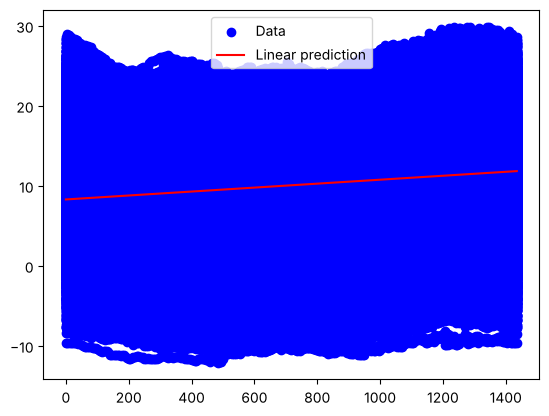

R^2 = 0.017


In [2]:
# ======================== CODE CELL 1 ========================
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

years = range(2011, 2017)
files = ['CRNS0101-05-%d-CA_Yosemite_Village_12_W.txt' % y for y in years]
usecols = [1, 2, 8]

data = [np.loadtxt(f, usecols=usecols) for f in files]
data = np.vstack(data)

# Map from HHmm to an integer
data[:, 1] = np.floor_divide(data[:, 1], 100) * 60 + np.mod(data[:, 1], 100)
valid = data[:, 2] > -1000

x_train = data[valid, 1].reshape(-1, 1)
y_train = data[valid, 2]
regr = linear_model.LinearRegression()
regr.fit(x_train, y_train)

x_predict = [[0], [1435]]
y_predict = regr.predict(x_predict)

plt.scatter(data[valid, 1], data[valid, 2], label='Data', color='b')
plt.plot(x_predict, y_predict, label='Linear prediction', color='r')
plt.legend(loc='best')
plt.show()
print("R^2 =", round(regr.score(x_train, y_train), 3))

## Question 3: why the straight line does so badly

R² ≈ 0.02: the line is barely better than predicting the mean. Temperature here moves on several timescales at
once, and a straight line in time of day can capture none of them:

- **Daily cycle.** Coldest about 4–5 am local, warmest about 1 pm (hourly means 8.3 → 12.9 °C). In UTC the cold
  point falls mid-axis and the warm point near the right edge, and the cycle wraps (23:55 sits next to 00:00).
  This needs a **periodic** shape: sine/cosine with a 24 h period, or bumps around a circle.
- **Seasonal cycle, bigger than the daily one.** Monthly means run 2.7 °C (Dec) to 19.1 °C (Aug). The model has
  no date input, so all of this lands as vertical scatter at every x. Needs a second input and a 1-year period.
- **The two interact.** The daily swing is wider in summer (≈8–9 °C) than in winter (≈6 °C).
- **Weather.** Warm and cold spells lasting days, not periodic. Needs local, flexible shapes in time.
- **Year-to-year drift.** Annual means range about 8.6–11.0 °C.

So the fix is not a better line but a better **basis**: give the model functions that can make these shapes and
keep the fit linear in the weights.

## Code Cell 2: RBF model

Two inputs instead of one:

- **time of day**, placed on a circle (cos, sin) so midnight wraps around, with 12 RBFs spaced around the clock
  for the daily cycle;
- **days since 1 Jan 2011**, with an RBF every 3 days for the seasons and multi-day weather.

That is 748 basis functions. The model is still linear in its parameters, so Ridge fits the 748 weights in one
step. It is fitted on one reading per hour (52k rows); readings 5 minutes apart are nearly identical.

RBFs: 12 daily + 736 slow
Score (R^2) on all 630854 readings = 0.933


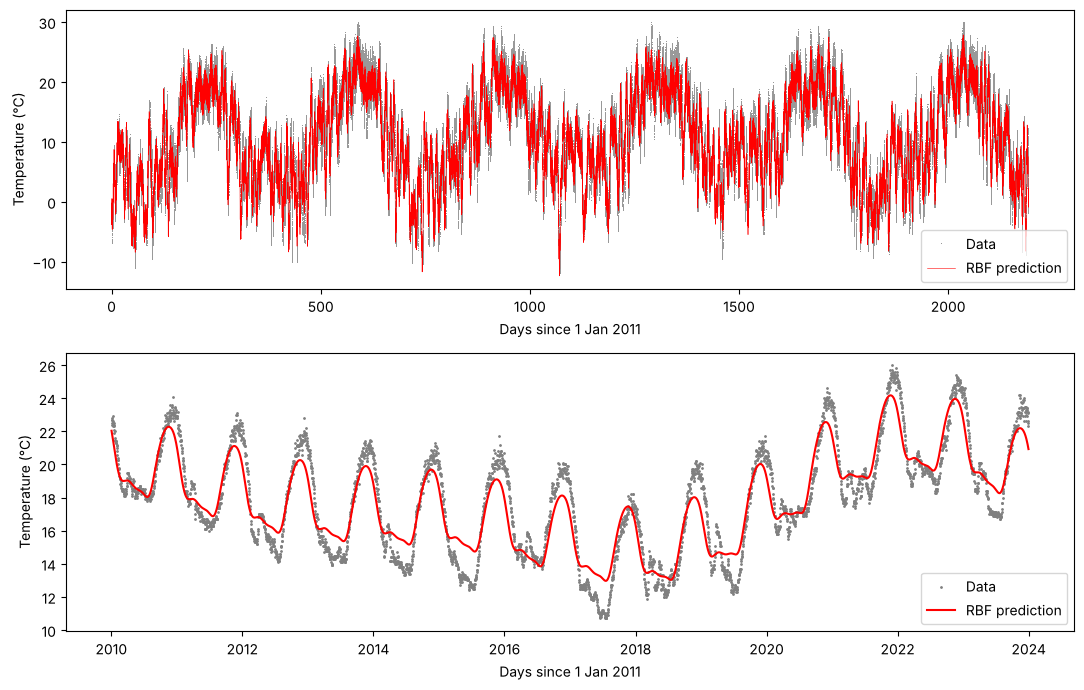

In [3]:
# ======================== CODE CELL 2 ========================
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt
import numpy as np

years = range(2011, 2017)
files = ['CRNS0101-05-%d-CA_Yosemite_Village_12_W.txt' % y for y in years]
data = np.vstack([np.loadtxt(f, usecols=[1, 2, 8]) for f in files])  # UTC date, UTC time, temp
data = data[data[:, 2] > -1000]                                      # drop missing (-9999)

ymd = data[:, 0].astype(int)
dates = np.array(['%04d-%02d-%02d' % (v // 10000, v // 100 % 100, v % 100) for v in ymd], dtype='datetime64[D]')
minute = np.floor_divide(data[:, 1], 100) * 60 + np.mod(data[:, 1], 100)
day = (dates - np.datetime64('2011-01-01')).astype(float) + minute / 1440.0
temp = data[:, 2]


def features(day, minute, spacing=3.0, width=1.0, n_daily=12):
    # Daily cycle: place time of day on a circle so 23:55 sits next to 00:00,
    # then put n_daily RBF centres evenly around the circle.
    ang = 2 * np.pi * minute / 1440.0
    c_ang = 2 * np.pi * np.arange(n_daily) / n_daily
    daily = rbf_kernel(np.c_[np.cos(ang), np.sin(ang)], np.c_[np.cos(c_ang), np.sin(c_ang)],
                       gamma=1.0 / (2 * (2 * np.pi / n_daily) ** 2))
    # Slow changes: one RBF every `spacing` days across all six years;
    # `width` is each RBF's standard deviation as a multiple of the spacing.
    centres = np.arange(-spacing, 2200 + spacing, spacing).reshape(-1, 1)
    slow = rbf_kernel(day.reshape(-1, 1), centres, gamma=1.0 / (2 * (width * spacing) ** 2))
    return np.hstack([daily, slow])


def predict(model, day, minute, **kw):
    # predict in chunks so the 630k x ~750 feature matrix is never held at once
    return np.concatenate([model.predict(features(day[i:i + 50000], minute[i:i + 50000], **kw))
                           for i in range(0, len(day), 50000)])


# Fit on one reading per hour (52k rows): readings 5 minutes apart are nearly identical.
sub = np.arange(0, len(temp), 12)
regr = Ridge(alpha=1e-3)
regr.fit(features(day[sub], minute[sub]), temp[sub])
pred = predict(regr, day, minute)
print("RBFs: 12 daily + %d slow" % (features(day[:1], minute[:1]).shape[1] - 12))
print("Score (R^2) on all %d readings = %.3f" % (len(temp), 1 - np.sum((temp - pred) ** 2) / np.sum((temp - temp.mean()) ** 2)))

fig, ax = plt.subplots(2, 1, figsize=(11, 7))
ax[0].plot(day, temp, ',', color='0.6', label='Data')
ax[0].plot(day, pred, lw=0.4, color='r', label='RBF prediction')
ax[0].set_xlabel('Days since 1 Jan 2011'); ax[0].set_ylabel('Temperature (°C)'); ax[0].legend(loc='lower right')
w = (day > 2010) & (day < 2024)  # zoom in: two weeks of July 2016
ax[1].plot(day[w], temp[w], '.', ms=2, color='0.5', label='Data')
ax[1].plot(day[w], pred[w], color='r', label='RBF prediction')
ax[1].set_xlabel('Days since 1 Jan 2011'); ax[1].set_ylabel('Temperature (°C)'); ax[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

## Code Cell 3: the metric

**R²** because the benchmark is stated in it; **RMSE** and **MAE** in °C because they say how far off a typical
prediction is (RMSE punishes large misses more). Scored twice: on the readings the model was fitted to, and on
whole days it never saw. Every 7th day is held out and the model refitted without it, since more RBFs always
improve the training fit and only unseen data shows when they start fitting noise.

In [4]:
# ======================== CODE CELL 3 ========================
# Uses day, minute, temp, features, predict, sub, pred from Code Cell 2.
def report(name, y, p):
    r = y - p
    print("%-36s R^2 = %.3f   RMSE = %.2f °C   MAE = %.2f °C"
          % (name, 1 - np.sum(r ** 2) / np.sum((y - y.mean()) ** 2), np.sqrt(np.mean(r ** 2)), np.mean(np.abs(r))))

line = np.polyfit(minute, temp, 1)
report("Cell 1 straight line", temp, np.polyval(line, minute))
report("Cell 2 RBF model, fitted data", temp, pred)

held = np.floor(day).astype(int) % 7 == 3
fit_rows = sub[~held[sub]]
m = Ridge(alpha=1e-3).fit(features(day[fit_rows], minute[fit_rows]), temp[fit_rows])
report("Cell 2 RBF model, unseen days", temp[held], predict(m, day[held], minute[held]))

Cell 1 straight line                 R^2 = 0.017   RMSE = 7.75 °C   MAE = 6.45 °C
Cell 2 RBF model, fitted data        R^2 = 0.933   RMSE = 2.03 °C   MAE = 1.56 °C


Cell 2 RBF model, unseen days        R^2 = 0.884   RMSE = 2.62 °C   MAE = 1.99 °C


## Code Cell 4: hyperparameter search (extension)

Searches the RBF **spacing** (which sets how many RBFs there are), the RBF **width**, and the ridge penalty
**alpha**. Ridge fits the heights (weights) for each setting. Every setting is scored by R² on the held-out days,
not on the training data, so a setting cannot win by memorising noise. The closest spacing tried is 2 days
(1,114 RBFs), which keeps the feature matrix under about 0.5 GB.

In [5]:
# ======================== CODE CELL 4 ========================
# Uses day, minute, temp, features, predict, sub from Code Cell 2.
import itertools, time
held = np.floor(day).astype(int) % 7 == 3
fit_rows, test_rows = sub[~held[sub]], sub[held[sub]]
results = []
t0 = time.time()
for spacing, width, alpha in itertools.product([30, 10, 5, 3, 2], [0.5, 1.0, 2.0], [1e-3, 1e-1]):
    kw = dict(spacing=spacing, width=width)
    m = Ridge(alpha=alpha).fit(features(day[fit_rows], minute[fit_rows], **kw), temp[fit_rows])
    r2 = m.score(features(day[test_rows], minute[test_rows], **kw), temp[test_rows])
    results.append((r2, spacing, width, alpha))
    print("spacing %2d days (%4d RBFs)  width %.1f  alpha %g  ->  unseen-day R^2 = %.3f"
          % (spacing, len(np.arange(-spacing, 2200 + spacing, spacing)) + 12, width, alpha, r2))
best = max(results)
print("\nbest: spacing %d days, width %.1f, alpha %g -> unseen-day R^2 = %.3f   (search took %.0f s)"
      % (best[1], best[2], best[3], best[0], time.time() - t0))

# Refit the best setting on every hourly reading and score it on all readings.
kw = dict(spacing=best[1], width=best[2])
final = Ridge(alpha=best[3]).fit(features(day[sub], minute[sub], **kw), temp[sub])
p = predict(final, day, minute, **kw)
print("best setting on all %d readings: R^2 = %.3f, RMSE = %.2f °C"
      % (len(temp), 1 - np.sum((temp - p) ** 2) / np.sum((temp - temp.mean()) ** 2), np.sqrt(np.mean((temp - p) ** 2))))

spacing 30 days (  88 RBFs)  width 0.5  alpha 0.001  ->  unseen-day R^2 = 0.650


spacing 30 days (  88 RBFs)  width 0.5  alpha 0.1  ->  unseen-day R^2 = 0.650
spacing 30 days (  88 RBFs)  width 1.0  alpha 0.001  ->  unseen-day R^2 = 0.651


spacing 30 days (  88 RBFs)  width 1.0  alpha 0.1  ->  unseen-day R^2 = 0.651
spacing 30 days (  88 RBFs)  width 2.0  alpha 0.001  ->  unseen-day R^2 = 0.641


spacing 30 days (  88 RBFs)  width 2.0  alpha 0.1  ->  unseen-day R^2 = 0.632


spacing 10 days ( 234 RBFs)  width 0.5  alpha 0.001  ->  unseen-day R^2 = 0.715


...

spacing  2 days (1114 RBFs)  width 1.0  alpha 0.001  ->  unseen-day R^2 = 0.931


spacing  2 days (1114 RBFs)  width 1.0  alpha 0.1  ->  unseen-day R^2 = 0.926


spacing  2 days (1114 RBFs)  width 2.0  alpha 0.001  ->  unseen-day R^2 = 0.870


spacing  2 days (1114 RBFs)  width 2.0  alpha 0.1  ->  unseen-day R^2 = 0.851

best: spacing 2 days, width 1.0, alpha 0.001 -> unseen-day R^2 = 0.931   (search took 60 s)


best setting on all 630854 readings: R^2 = 0.961, RMSE = 1.55 °C


## Extension answers

**1. What performance were you able to achieve?**

The Cell 2 model (an RBF every 3 days plus 12 around the clock, 748 in all) reaches **R² = 0.933** on all
630,854 readings and **0.884 on whole days it never saw**. The Cell 4 search found a better setting: an RBF every
**2 days**, width 1.0 × spacing, alpha 0.001 (1,114 RBFs). It scores **R² = 0.931 on unseen days**, and refitted on
all the data, **R² = 0.961 with RMSE 1.55 °C**. Both are above the 0.82 benchmark.

What the search shows:

- **The number of RBFs is the main lever, as the hint says.** Unseen-day R² climbs from 0.65 with an RBF every
  30 days to 0.81 at 5 days, 0.88 at 3 days and 0.93 at 2 days. Coarse spacing captures the seasons; fine spacing
  is what captures multi-day weather.
- **Width matters next.** Width 2.0 is consistently worst (it blurs neighbouring weather spells together); 0.5 and
  1.0 are close, with 1.0 slightly better.
- **Alpha barely matters** at these settings (differences in the third decimal), because 52k hourly rows are
  plenty for ~1,100 weights.
- **The best value is at the edge of the grid** (2 days was the finest spacing tried), so finer spacing may do
  better still. Spacing was stopped at 2 days to keep the feature matrix under about 0.5 GB.

**Caveat worth saying in class.** These held-out days sit between training days, so the score measures
*filling in* the record, not forecasting. The slow RBFs fit each specific week's weather, and RBFs fall to zero
away from their centres, so this model cannot predict 2017. A calendar-only model (season and time of day, no
week-specific RBFs) tested on an entire unseen year reaches only about R² 0.64; the rest is weather that the
calendar cannot know.

**2. What would applying lasso do?**

Ridge (used here) shrinks every weight a little but keeps all the RBFs. Lasso's L1 penalty pushes many weights
to **exactly zero**, so it chooses which RBFs to keep:

- It would drop RBFs that add nothing, for example in calm stretches where temperature just follows the season,
  and keep them where weather changes quickly. The model becomes sparser and easier to read, and you can start
  with too many RBFs and let lasso prune them.
- Neighbouring RBFs overlap and are highly correlated, and lasso tends to keep one of a correlated group
  arbitrarily, so its fitted curve can be less smooth than ridge's.
- With a strong penalty it removes RBFs that carry real structure, and R² drops.
- It has no closed-form solution, so it is slower to fit than ridge.

In probabilistic terms, ridge is the MAP estimate under a Gaussian prior on the weights and lasso under a
Laplace prior, whose sharp peak at zero is what produces exact zeros.